# **CA3 - Reinforcement Learning**

In [1]:
import gymnasium as gym
import math
import numpy as np
from collections import deque
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

### **PART 1: AGENT IMPLEMENTATION**

In [2]:
if not hasattr(np, "bool8"):
    np.bool8 = np.bool_

In [3]:
class QLearningAgent:
    def __init__(
        self,
        env,
        buckets=(40, 40),
        alpha=0.05,
        gamma=0.99,
        epsilon_strategy='exponential',
        episodes=100000,
        seed=400
    ):
        self.env = env
        self.buckets = buckets
        self.alpha = alpha
        self.gamma = gamma
        self.episodes = episodes
        self.epsilon_strategy = epsilon_strategy
        self.seed = seed

        self.rng = np.random.default_rng(seed)
        self.env.action_space.seed(seed) 
        self.lower_bounds = self.env.observation_space.low
        self.upper_bounds = self.env.observation_space.high

        self.Q_table = np.zeros(self.buckets + (self.env.action_space.n,))

        self.threshold = self.env.spec.reward_threshold
        print('threshold:', self.threshold)

    def reset_env(self, episode=0):
        reset_result = self.env.reset(seed=self.seed + episode)

        if isinstance(reset_result, tuple):
            obs = reset_result[0]
        else:
            obs = reset_result

        return obs

    def discretize_state(self, obs):
        """
        Convert continuous observation to a discrete state.
        TODO: implement discretization based on observation bounds.
        """
        ratios = [(obs[i] - self.lower_bounds[i]) / (self.upper_bounds[i] - self.lower_bounds[i]) 
              for i in range(len(obs))]
    
        discretized = [int(round((self.buckets[i] - 1) * ratios[i])) 
                   for i in range(len(obs))]
    
        discretized = [min(self.buckets[i] - 1, max(0, d)) for i, d in enumerate(discretized)]
    
        return tuple(discretized)

    def choose_action(self, state, epsilon):
        """
        Select an action using epsilon-greedy policy.
        TODO: implement exploration vs exploitation.
        """
        # اکتشاف (Exploration): با احتمال epsilon یک عمل تصادفی انتخاب کن
        if self.rng.random() < epsilon:
            return self.env.action_space.sample()
    
        # بهره‌برداری (Exploitation): عمل با بیشترین مقدار Q را انتخاب کن
        # در صورت تساوی، کوچکترین اندیس را برمی‌گردانیم
        q_values = self.Q_table[state]
        max_q = np.max(q_values)
        # پیدا کردن تمام actionهایی که max مقدار را دارند
        max_actions = np.where(q_values == max_q)[0]
        # انتخاب تصادفی بین actionهای با max مقدار
        return self.rng.choice(max_actions)

    def get_epsilon(self, episode):
        """
        Return epsilon for current episode.
        TODO: implement epsilon decay strategy.
        """
        # TODO: implement constant / linear / exponential / logarithmic decay

        # مقدار اولیه epsilon
        epsilon_start = 1.0
        epsilon_end = 0.01
    
        if self.epsilon_strategy == 'constant':
            epsilon = 0.1
        
        elif self.epsilon_strategy == 'linear':
            decay_steps = self.episodes * 0.3 
            epsilon = epsilon_start - (episode / decay_steps) * (epsilon_start - epsilon_end)
            epsilon = max(epsilon_end, min(epsilon_start, epsilon))
        
        elif self.epsilon_strategy == 'exponential':
         
            decay_rate = -np.log(epsilon_end / epsilon_start) / (self.episodes * 0.3)
            epsilon = epsilon_end + (epsilon_start - epsilon_end) * np.exp(-decay_rate * episode)
            epsilon = max(epsilon_end, min(epsilon_start, epsilon))
        
        elif self.epsilon_strategy == 'logarithmic':
            epsilon = epsilon_end + (epsilon_start - epsilon_end) * (1 - np.log(episode + 1) / np.log(self.episodes))
            epsilon = max(epsilon_end, min(epsilon_start, epsilon))
        
        else:
            decay_rate = -np.log(epsilon_end / epsilon_start) / (self.episodes * 0.3)
            epsilon = epsilon_end + (epsilon_start - epsilon_end) * np.exp(-decay_rate * episode)
            epsilon = max(epsilon_end, min(epsilon_start, epsilon))
    
        return epsilon

    def train(self):
        """
        Train the Q-learning agent.
        TODO: complete the training loop, logging, and stopping criteria.
        """
        scores_window = deque(maxlen=100)

        scores_array = []
        avg_scores_array = []
        epsilons_array = []
        shaped_scores_array = []

        for episode in range(self.episodes):
            # TODO: reset environment and get initial state
            # compute epsilon for this episode
            # run episode until termination
            obs = self.reset_env(episode)
            state = self.discretize_state(obs)
            total_reward = 0
            epsilon = self.get_epsilon(episode)

            done =  False

            while not done:
                # TODO: choose action, take a step in the environment
                # discretize next state, update Q-table, accumulate rewards
                action = self.choose_action(state, epsilon)
                step_result = self.env.step(action)
            
                # بررسی فرمت خروجی env.step (ممکن است 4 یا 5 مقدار برگرداند)
                if len(step_result) == 4:
                    next_obs, reward, done, info = step_result
                else:
                    next_obs, reward, terminated, truncated, info = step_result
                    done = terminated or truncated
                next_state = self.discretize_state(next_obs)
            
                best_next_q = np.max(self.Q_table[next_state])
                td_target = reward + self.gamma * best_next_q
                td_error = td_target - self.Q_table[state][action]
                self.Q_table[state][action] += self.alpha * td_error
            
                state = next_state
                total_reward += reward

            # TODO: log episode reward ,compute moving average, 
            # decay / store epsilon if needed, check stopping condition if required
            scores_array.append(total_reward)
            scores_window.append(total_reward)
            avg_score = np.mean(scores_window)
            avg_scores_array.append(avg_score)
            epsilons_array.append(epsilon)
            shaped_scores_array.append(total_reward)  # برای reward shaping بعداً استفاده می‌شود
        
            # نمایش پیشرفت هر 1000 اپیزود
            if episode % 1000 == 0:
                print(f"Episode {episode}, Avg Score (last 100): {avg_score:.2f}, Epsilon: {epsilon:.4f}")
        
            # شرط توقف: اگر میانگین 100 اپیزود اخیر از آستانه بیشتر شد
            # آستانه معمولاً -110 برای MountainCar است
            if avg_score >= self.threshold and episode >= 100:
                print(f"Solved at episode {episode}! Average score: {avg_score:.2f}")
                break

        return scores_array, avg_scores_array, epsilons_array, shaped_scores_array

    def evaluate(self, episodes=100):
        eval_scores = []
        """
        TODO: implement evaluation logic
        """    
        for episode in range(episodes):
            obs = self.reset_env(episode)
            state = self.discretize_state(obs)
            total_reward = 0
            done = False
        
            while not done:
            # بدون اکتشاف (epsilon = 0)
                action = self.choose_action(state, epsilon=0)
                step_result = self.env.step(action)
            
                if len(step_result) == 4:
                    next_obs, reward, done, info = step_result
                else:
                    next_obs, reward, terminated, truncated, info = step_result
                    done = terminated or truncated
            
                state = self.discretize_state(next_obs)
                total_reward += reward
        
            eval_scores.append(total_reward)
            print(f"Evaluation Episode {episode + 1}/{episodes}: Reward = {total_reward}")
    
        # گزارش آمار
        eval_scores = np.array(eval_scores)
        print(f"\n--- Evaluation Results ---")
        print(f"Mean reward: {np.mean(eval_scores):.2f}")
        print(f"Best reward: {np.max(eval_scores):.2f}")
        print(f"Worst reward: {np.min(eval_scores):.2f}")
        print(f"Standard deviation: {np.std(eval_scores):.2f}")
    
        return eval_scores

In [36]:
env = gym.make('MountainCar-v0')
visual_agent = QLearningAgent(
    env, 
    buckets=(40, 40), 
    epsilon_strategy='exponential', 
    episodes=100000,
    seed=400
)

scores, avg_scores, epsilons, shaped_scores = visual_agent.train()

threshold: -110.0
Episode 0, Avg Score (last 100): -200.00, Epsilon: 1.0000
Episode 1000, Avg Score (last 100): -200.00, Epsilon: 0.8591
Episode 2000, Avg Score (last 100): -200.00, Epsilon: 0.7383
Episode 3000, Avg Score (last 100): -200.00, Epsilon: 0.6346
Episode 4000, Avg Score (last 100): -200.00, Epsilon: 0.5458
Episode 5000, Avg Score (last 100): -200.00, Epsilon: 0.4695
Episode 6000, Avg Score (last 100): -199.69, Epsilon: 0.4041
Episode 7000, Avg Score (last 100): -198.46, Epsilon: 0.3480
Episode 8000, Avg Score (last 100): -197.23, Epsilon: 0.2999
Episode 9000, Avg Score (last 100): -195.86, Epsilon: 0.2587
Episode 10000, Avg Score (last 100): -189.69, Epsilon: 0.2233
Episode 11000, Avg Score (last 100): -188.45, Epsilon: 0.1929
Episode 12000, Avg Score (last 100): -186.89, Epsilon: 0.1669
Episode 13000, Avg Score (last 100): -196.08, Epsilon: 0.1446
Episode 14000, Avg Score (last 100): -194.82, Epsilon: 0.1254
Episode 15000, Avg Score (last 100): -176.35, Epsilon: 0.1090
Epi

In [37]:
def watch_agent(agent, episodes=5):
    env = gym.make("MountainCar-v0", render_mode="human")

    for episode in range(episodes):
        reset_result = env.reset(seed=agent.seed + 200000 + episode)

        if isinstance(reset_result, tuple):
            obs = reset_result[0]
        else:
            obs = reset_result

        state = agent.discretize_state(obs)
        done = False
        total_reward = 0

        while not done:
            action = np.argmax(agent.Q_table[state])

            step_result = env.step(action)

            if len(step_result) == 4:
                next_obs, reward, done, _ = step_result
            else:
                next_obs, reward, terminated, truncated, _ = step_result
                done = terminated or truncated

            state = agent.discretize_state(next_obs)
            total_reward += reward

        print(f"Episode {episode + 1} reward: {total_reward}")

    env.close()

In [38]:
watch_agent(visual_agent, episodes=5)

Episode 1 reward: -113.0
Episode 2 reward: -118.0
Episode 3 reward: -152.0
Episode 4 reward: -115.0
Episode 5 reward: -116.0


### **PART 2: AGENT TRAINING**

In [39]:
scores, avg_scores, epsilons, shaped_scores = visual_agent.train()

Episode 0, Avg Score (last 100): -200.00, Epsilon: 1.0000
Episode 1000, Avg Score (last 100): -200.00, Epsilon: 0.8591
Episode 2000, Avg Score (last 100): -200.00, Epsilon: 0.7383
Episode 3000, Avg Score (last 100): -200.00, Epsilon: 0.6346
Episode 4000, Avg Score (last 100): -198.56, Epsilon: 0.5458
Episode 5000, Avg Score (last 100): -190.69, Epsilon: 0.4695
Episode 6000, Avg Score (last 100): -179.99, Epsilon: 0.4041
Episode 7000, Avg Score (last 100): -172.59, Epsilon: 0.3480
Episode 8000, Avg Score (last 100): -164.19, Epsilon: 0.2999
Episode 9000, Avg Score (last 100): -159.99, Epsilon: 0.2587
Episode 10000, Avg Score (last 100): -151.82, Epsilon: 0.2233
Episode 11000, Avg Score (last 100): -144.33, Epsilon: 0.1929
Episode 12000, Avg Score (last 100): -139.34, Epsilon: 0.1669
Episode 13000, Avg Score (last 100): -137.89, Epsilon: 0.1446
Episode 14000, Avg Score (last 100): -147.77, Epsilon: 0.1254
Episode 15000, Avg Score (last 100): -140.07, Epsilon: 0.1090
Episode 16000, Avg Sc

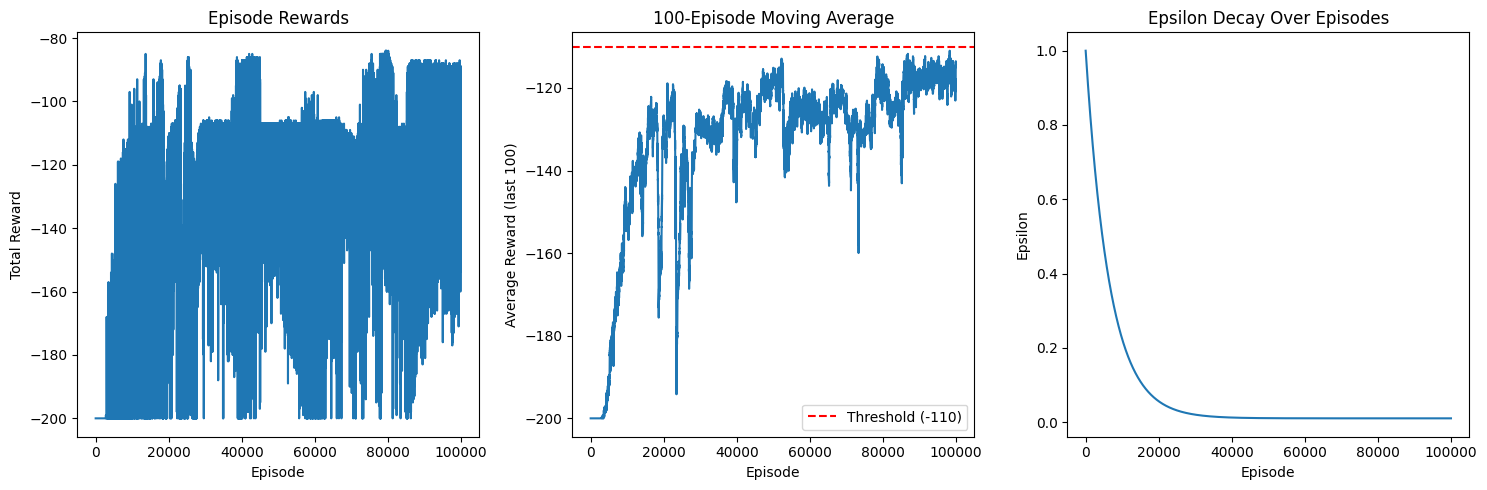

In [ ]:
# TODO: plot episode rewards
# TODO: plot 100-episode moving average
# TODO: plot epsilon over episodes
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.plot(scores)
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.title('Episode Rewards')

plt.subplot(1, 3, 2)
plt.plot(avg_scores)
plt.xlabel('Episode')
plt.ylabel('Average Reward (last 100)')
plt.title('100-Episode Moving Average')
plt.axhline(y=-110, color='r', linestyle='--', label='Threshold (-110)')
plt.legend()

plt.subplot(1, 3, 3)
plt.plot(epsilons)
plt.xlabel('Episode')
plt.ylabel('Epsilon')
plt.title('Epsilon Decay Over Episodes')

plt.tight_layout()
plt.show()

### **PART 3: AGENT EVALUATION**

In [41]:
eval_scores = visual_agent.evaluate(episodes=100)

print("Evaluation without exploration")
print("Mean evaluation score:", np.mean(eval_scores))
print("Best evaluation score:", np.max(eval_scores))
print("Worst evaluation score:", np.min(eval_scores))

Evaluation Episode 1/100: Reward = -106.0
Evaluation Episode 2/100: Reward = -140.0
Evaluation Episode 3/100: Reward = -105.0
Evaluation Episode 4/100: Reward = -105.0
Evaluation Episode 5/100: Reward = -105.0
Evaluation Episode 6/100: Reward = -99.0
Evaluation Episode 7/100: Reward = -105.0
Evaluation Episode 8/100: Reward = -106.0
Evaluation Episode 9/100: Reward = -138.0
Evaluation Episode 10/100: Reward = -105.0
Evaluation Episode 11/100: Reward = -106.0
Evaluation Episode 12/100: Reward = -105.0
Evaluation Episode 13/100: Reward = -141.0
Evaluation Episode 14/100: Reward = -105.0
Evaluation Episode 15/100: Reward = -106.0
Evaluation Episode 16/100: Reward = -140.0
Evaluation Episode 17/100: Reward = -106.0
Evaluation Episode 18/100: Reward = -89.0
Evaluation Episode 19/100: Reward = -106.0
Evaluation Episode 20/100: Reward = -89.0
Evaluation Episode 21/100: Reward = -141.0
Evaluation Episode 22/100: Reward = -105.0
Evaluation Episode 23/100: Reward = -138.0
Evaluation Episode 24/1

In [42]:
watch_agent(visual_agent, episodes=5)

Episode 1 reward: -106.0
Episode 2 reward: -105.0
Episode 3 reward: -102.0
Episode 4 reward: -106.0
Episode 5 reward: -106.0


### **PART 4: EPSILON STRATEGY AND DISCRETIZATION GRANUALITY EXPERIMENTS**

In [43]:
def plot_training_result(scores, avg_scores, epsilons, title):
    """
    Plot training performance of the agent.

    TODO:
    1. Plot episode rewards.
    2. Plot moving average reward over the last 100 episodes.
    3. Plot epsilon values over episodes.
    """

    plt.figure(figsize=(15, 5))
    
    plt.subplot(1, 3, 1)
    plt.plot(scores)
    plt.xlabel('Episode')
    plt.ylabel('Total Reward')
    plt.title(title + ' - Episode Rewards')
    
    plt.subplot(1, 3, 2)
    plt.plot(avg_scores)
    plt.xlabel('Episode')
    plt.ylabel('Average Reward (last 100)')
    plt.title(title + ' - Moving Average')
    plt.axhline(y=-110, color='r', linestyle='--', label='Threshold (-110)')
    plt.legend()
    
    plt.subplot(1, 3, 3)
    plt.plot(epsilons)
    plt.xlabel('Episode')
    plt.ylabel('Epsilon')
    plt.title(title + ' - Epsilon Decay')
    
    plt.tight_layout()
    plt.show()

def run_epsilon_experiments(episodes=100000, buckets=(40, 40), seed=400):
    """
    Run experiments comparing different epsilon strategies.

    TODO:
    1. Train agents using different epsilon strategies.
    2. Store training results.
    3. Evaluate the trained agents.
    4. Plot training results for each strategy.
    5. Plot comparison charts between strategies.
    """

    strategies = ['constant', 'linear', 'logarithmic', 'exponential']
    results = {}

    print("--- Running Epsilon Strategy Experiments ---")

    # TODO: iterate over epsilon strategies
    for strategy in strategies:
        print(f"\nTraining with {strategy} strategy...")
        agent = QLearningAgent(
            env,
            buckets=(40, 40),
            epsilon_strategy=strategy,
            episodes=episodes,
            seed=seed
        )
        scores, avg_scores, epsilons, _ = agent.train()
        eval_scores = agent.evaluate(episodes=100)
        results[strategy] = {
            'scores': scores,
            'avg_scores': avg_scores,
            'epsilons': epsilons,
            'eval_mean': np.mean(eval_scores),
            'eval_std': np.std(eval_scores)
        }
        print(f"{strategy} - Mean evaluation score: {np.mean(eval_scores):.2f}")

    # TODO: create a plot comparing average rewards for all strategies
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    for strategy in strategies:
        plt.plot(results[strategy]['avg_scores'], label=strategy)
    plt.xlabel('Episode')
    plt.ylabel('Average Reward (last 100)')
    plt.title('Comparison of Epsilon Strategies')
    plt.axhline(y=-110, color='r', linestyle='--', label='Threshold (-110)')
    plt.legend()
    plt.grid(True)
    # TODO: create a plot comparing epsilon schedules for all strategies
    plt.subplot(1, 2, 2)
    for strategy in strategies:
        plt.plot(results[strategy]['epsilons'], label=strategy)
    plt.xlabel('Episode')
    plt.ylabel('Epsilon')
    plt.title('Epsilon Decay Comparison')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return results


def run_bucket_experiments(episodes=100000, seed=400):
    """
    Run experiments with different discretization bucket sizes.

    TODO:
    1. Train agents with different discretization grids.
    2. Compare their training performance.
    3. Plot the results.
    """
    env = gym.make('MountainCar-v0')
    agent = QLearningAgent(env, buckets=(40, 40), episodes=100, seed=400)

    obs = agent.reset_env(0)
    state = agent.discretize_state(obs)
    print("Observation:", obs)
    print("Discretized state:", state)
    print("Q_table shape:", agent.Q_table.shape)
    print("Lower bounds:", agent.lower_bounds)
    print("Upper bounds:", agent.upper_bounds)

    action = agent.choose_action(state, epsilon=1.0)
    print("Chosen action:", action)

    step_result = env.step(action)
    if len(step_result) == 4:
        next_obs, reward, done, info = step_result
    else:
        next_obs, reward, terminated, truncated, info = step_result
        done = terminated or truncated

    next_state = agent.discretize_state(next_obs)
    print("Next observation:", next_obs)
    print("Next state:", next_state)
    print("Reward:", reward)
    print("Done:", done)

    best_next_q = np.max(agent.Q_table[next_state])
    print("Best next Q:", best_next_q)

    td_target = reward + agent.gamma * best_next_q
    td_error = td_target - agent.Q_table[state][action]
    agent.Q_table[state][action] += agent.alpha * td_error
    print("Updated Q value:", agent.Q_table[state][action])
    grids = [(5, 5), (100, 100)]
    results = {}

    print("\n--- Running Discretization Bucket Experiments ---")

        # TODO: iterate over discretization grids
    for grid in grids:
        print(f"\nTraining with buckets = {grid}...")
        agent = QLearningAgent(
            env,
            buckets=grid,
            epsilon_strategy='exponential',
            episodes=episodes,
            seed=seed
        )   
        scores, avg_scores, epsilons, _ = agent.train()
        eval_scores = agent.evaluate(episodes=100)
        results[grid] = {
            'scores': scores,
            'avg_scores': avg_scores,
            'epsilons': epsilons,
            'eval_mean': np.mean(eval_scores),
            'eval_std': np.std(eval_scores)
        }
        print(f"Buckets {grid} - Mean evaluation score: {np.mean(eval_scores):.2f}")

        # TODO: plot comparison of average rewards for different grids
        plt.figure(figsize=(10, 6))
        for grid in grids:
            plt.plot(results[grid]['avg_scores'], label=f'Buckets {grid[0]}x{grid[1]}')
        plt.xlabel('Episode')
        plt.ylabel('Average Reward (last 100)')
        plt.title('Comparison of Discretization Granularity')
        plt.axhline(y=-110, color='r', linestyle='--', label='Threshold (-110)')
        plt.legend()
        plt.grid(True)
        plt.show()
        
        return results

--- Running Epsilon Strategy Experiments ---

Training with constant strategy...
threshold: -110.0
Episode 0, Avg Score (last 100): -200.00, Epsilon: 0.1000
Episode 1000, Avg Score (last 100): -200.00, Epsilon: 0.1000
Episode 2000, Avg Score (last 100): -200.00, Epsilon: 0.1000
Episode 3000, Avg Score (last 100): -200.00, Epsilon: 0.1000
Episode 4000, Avg Score (last 100): -200.00, Epsilon: 0.1000
Episode 5000, Avg Score (last 100): -197.79, Epsilon: 0.1000
Episode 6000, Avg Score (last 100): -199.21, Epsilon: 0.1000
Episode 7000, Avg Score (last 100): -198.29, Epsilon: 0.1000
Episode 8000, Avg Score (last 100): -197.10, Epsilon: 0.1000
Episode 9000, Avg Score (last 100): -192.01, Epsilon: 0.1000
Episode 10000, Avg Score (last 100): -187.58, Epsilon: 0.1000
Episode 11000, Avg Score (last 100): -177.61, Epsilon: 0.1000
Episode 12000, Avg Score (last 100): -197.46, Epsilon: 0.1000
Episode 13000, Avg Score (last 100): -187.02, Epsilon: 0.1000
Episode 14000, Avg Score (last 100): -178.87, 

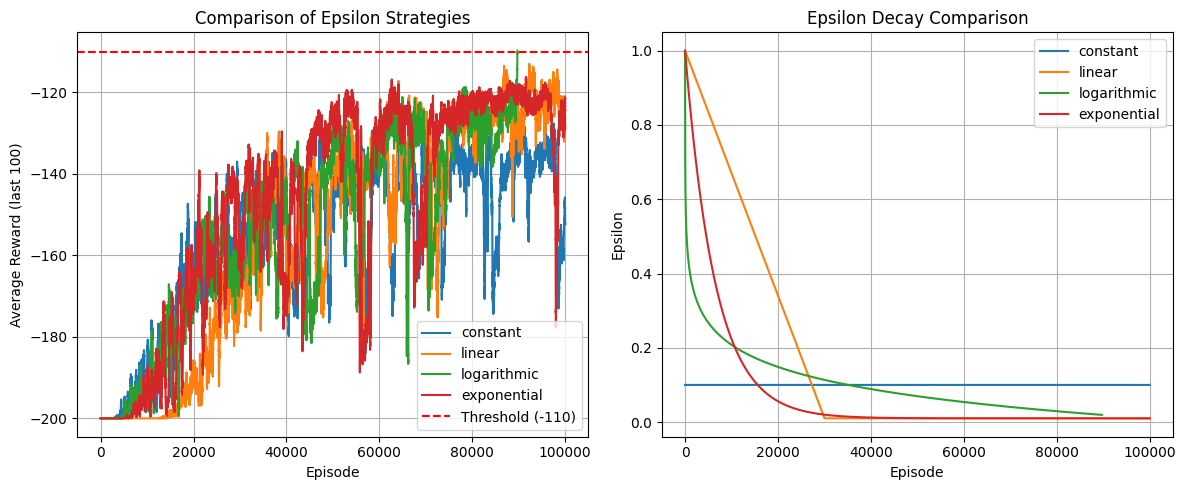

In [44]:
epsilon_results = run_epsilon_experiments(
    episodes=100000,
    buckets=(40, 40),
    seed=400
)

In [56]:
def fixed_get_epsilon(self, episode):
    epsilon_start = 1.0
    epsilon_end = 0.01
    decay_rate = -np.log(epsilon_end / epsilon_start) / (self.episodes * 0.3)
    epsilon = epsilon_end + (epsilon_start - epsilon_end) * np.exp(-decay_rate * episode)
    return max(epsilon_end, min(epsilon_start, epsilon))

QLearningAgent.get_epsilon = fixed_get_epsilon


Training with buckets = (5, 5)...
threshold: -110.0
Episode 0, Avg Score (last 100): -200.00, Epsilon: 1.0000
Episode 1000, Avg Score (last 100): -200.00, Epsilon: 0.8591
Episode 2000, Avg Score (last 100): -200.00, Epsilon: 0.7383
Episode 3000, Avg Score (last 100): -200.00, Epsilon: 0.6346
Episode 4000, Avg Score (last 100): -200.00, Epsilon: 0.5458
Episode 5000, Avg Score (last 100): -200.00, Epsilon: 0.4695
Episode 6000, Avg Score (last 100): -200.00, Epsilon: 0.4041
Episode 7000, Avg Score (last 100): -200.00, Epsilon: 0.3480
Episode 8000, Avg Score (last 100): -200.00, Epsilon: 0.2999
Episode 9000, Avg Score (last 100): -200.00, Epsilon: 0.2587
Episode 10000, Avg Score (last 100): -200.00, Epsilon: 0.2233
Episode 11000, Avg Score (last 100): -200.00, Epsilon: 0.1929
Episode 12000, Avg Score (last 100): -200.00, Epsilon: 0.1669
Episode 13000, Avg Score (last 100): -200.00, Epsilon: 0.1446
Episode 14000, Avg Score (last 100): -200.00, Epsilon: 0.1254
Episode 15000, Avg Score (last

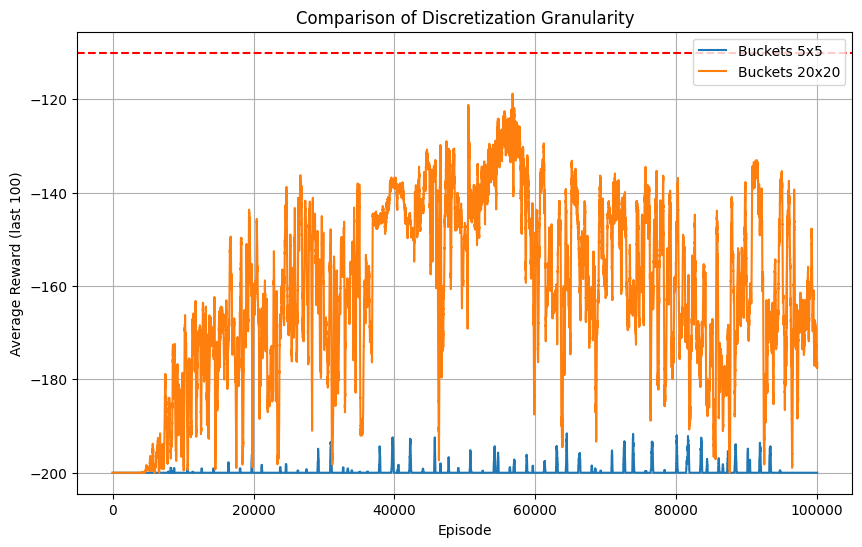

In [59]:
def run_bucket_experiments_fast(episodes=8000, seed=400):
    grids = [(5, 5), (20, 20)]
    results = {}
    
    for grid in grids:
        print(f"\nTraining with buckets = {grid}...")
        agent = QLearningAgent(
            env,
            buckets=grid,
            epsilon_strategy='exponential',
            episodes=episodes,
            seed=seed
        )
        scores, avg_scores, epsilons, _ = agent.train()
        eval_scores = agent.evaluate(episodes=50)
        results[grid] = {
            'avg_scores': avg_scores,
            'eval_mean': np.mean(eval_scores)
        }
        print(f"Buckets {grid} - Mean evaluation score: {np.mean(eval_scores):.2f}")
    
    plt.figure(figsize=(10, 6))
    for grid in grids:
        plt.plot(results[grid]['avg_scores'], label=f'Buckets {grid[0]}x{grid[1]}')
    plt.xlabel('Episode')
    plt.ylabel('Average Reward (last 100)')
    plt.title('Comparison of Discretization Granularity')
    plt.axhline(y=-110, color='r', linestyle='--')
    plt.legend()
    plt.grid(True)
    plt.show()
    
    return results

bucket_results = run_bucket_experiments_fast(episodes=100000 , seed=400)

### **PART 5: 3D VALUE FUNCTION VISUALIZATION**

In [46]:
def plot_value_function(agent):
    """
    Plot the learned state-value function V(s) = max_a Q(s, a) as a 3D surface.

    TODO:
    1. Compute V(s) = max_a Q(s, a) from the agent's Q-table.
    2. Mark unvisited states (where all Q-values are zero) as NaN so they are not plotted.
    3. Create position and velocity ranges based on the agent's discretization.
    4. Create a 3D surface plot over position, velocity, and V(s).
    """

    V = np.max(agent.Q_table, axis=2)
    
    visit_count = np.sum(agent.Q_table, axis=2)
    V = np.where(visit_count == 0, np.nan, V)
    
    pos_buckets = np.linspace(agent.lower_bounds[0], agent.upper_bounds[0], agent.buckets[0])
    vel_buckets = np.linspace(agent.lower_bounds[1], agent.upper_bounds[1], agent.buckets[1])
    
    pos_grid, vel_grid = np.meshgrid(pos_buckets, vel_buckets)
    
    fig = plt.figure(figsize=(12, 8))
    ax = fig.add_subplot(111, projection='3d')
    
    surf = ax.plot_surface(pos_grid, vel_grid, V.T, cmap='viridis', edgecolor='none', alpha=0.8)
    
    ax.set_xlabel('Position')
    ax.set_ylabel('Velocity')
    ax.set_zlabel('Value V(s) = max_a Q(s,a)')
    ax.set_title('Value Function Visualization')
    
    fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10)
    
    plt.show()

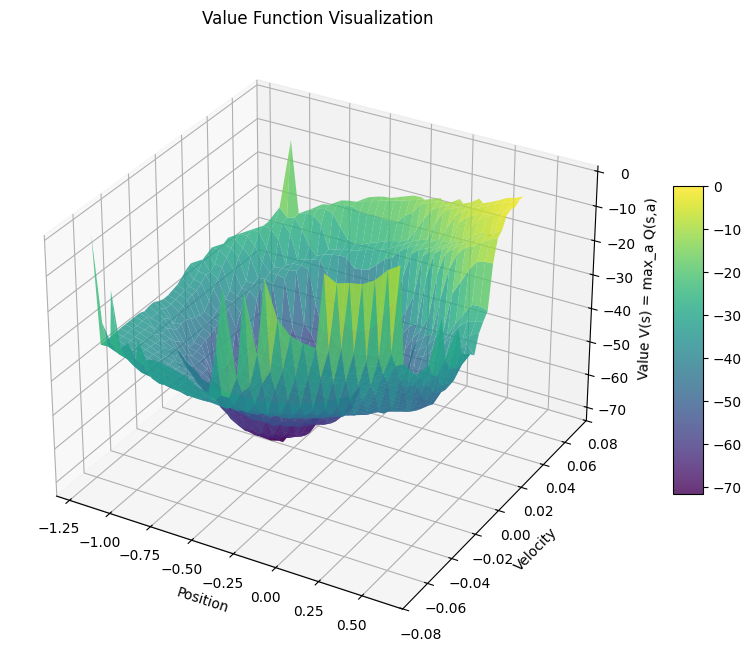

In [47]:
plot_value_function(visual_agent)

### ‌**PART 6: REWARD SHAPING (BONUS)**

In [73]:
class ShapedCarAgent:
    def __init__(self, env, buckets=(20, 20), alpha=0.3, gamma=0.99, episodes=2000, mode='original', seed=40):
        self.env = env
        self.buckets = buckets
        self.alpha = alpha
        self.gamma = gamma
        self.episodes = episodes
        self.mode = mode
        self.seed = seed
        self.rng = np.random.default_rng(seed)
        
        self.lower_bounds = self.env.observation_space.low
        self.upper_bounds = self.env.observation_space.high
        self.Q_table = np.zeros(self.buckets + (self.env.action_space.n,))

    def discretize_state(self, obs):
        """
        Convert continuous observation to a discrete state index.

        TODO:
        1. Scale each component of obs to [0, 1] using lower_bounds and upper_bounds.
        2. Map the scaled value to a bucket index in [0, buckets[i] - 1].
        3. Clip the index to ensure it lies within valid range.
        4. Return the discrete state as a tuple of indices.
        """

        if isinstance(obs, dict):
            obs = obs['observation']
        
        ratios = [(obs[i] - self.lower_bounds[i]) / (self.upper_bounds[i] - self.lower_bounds[i]) for i in range(len(obs))]
        discretized = [int(round((self.buckets[i] - 1) * ratios[i])) for i in range(len(obs))]
        discretized = [min(self.buckets[i] - 1, max(0, d)) for i, d in enumerate(discretized)]
        return tuple(discretized)

    def choose_action(self, state, epsilon):
        """
        Select an action using an epsilon-greedy policy.

        TODO:
        1. With probability epsilon, select a random action (exploration).
        2. Otherwise, select the greedy action (argmax over Q_table at this state).
        3. Return the selected action.
        """
        if self.rng.random() < epsilon:
            return self.env.action_space.sample()
        q_values = self.Q_table[state]
        max_q = np.max(q_values)
        max_actions = np.where(q_values == max_q)[0]
        return self.rng.choice(max_actions)

    def get_epsilon(self, episode):
        """
        Compute epsilon for the given episode.
        TODO:
        1. Implement an epsilon schedule (e.g., logarithmic decay, linear decay, etc.).
        2. Make sure epsilon stays within [0.01, 1.0].
        """
        epsilon_start = 1.0
        epsilon_end = 0.01
        decay_rate = -np.log(epsilon_end / epsilon_start) / (self.episodes * 0.3)
        epsilon = epsilon_end + (epsilon_start - epsilon_end) * np.exp(-decay_rate * episode)
        epsilon = max(epsilon_end, min(epsilon_start, epsilon))
        return epsilon
    def train(self):
        """
        Train the shaped Q-learning agent.

        Returns:
            scores_array: list of original (environment) rewards per episode.
            success_array: list of 0/1 flags indicating whether the goal was reached.
        
        TODO:
        1. For each episode:
           - Reset the environment (optionally using a different seed per episode).
           - Discretize the initial observation.
           - Compute epsilon using get_epsilon.
        2. Run the episode loop:
           - Choose an action using epsilon-greedy.
           - Step the environment.
           - Discretize the next observation.
           - Compute a learning reward that depends on `mode`
           - Accumulate the original environment reward for logging.
        3. Log:
           - Append the total original reward to scores_array.
           - Append 1 to success_array if the goal was reached, else 0.
        """
        """
        TODO:
        Run reward shaping experiments and compare different modes
        """

        scores_array = []
        success_array = []
        
        for episode in range(self.episodes):
            reset_result = self.env.reset(seed=self.seed + episode)
            if isinstance(reset_result, tuple):
                obs = reset_result[0]
            else:
                obs = reset_result
            if isinstance(obs, dict):
                obs = obs['observation']
            
            state = self.discretize_state(obs)
            epsilon = self.get_epsilon(episode)
            total_reward = 0
            goal_reached = False
            done = False
            
            while not done:
                action = self.choose_action(state, epsilon)
                step_result = self.env.step(action)
                
                if len(step_result) == 4:
                    next_obs, reward, done, info = step_result
                else:
                    next_obs, reward, terminated, truncated, info = step_result
                    done = terminated or truncated
                
                if isinstance(next_obs, dict):
                    next_obs = next_obs['observation']
                
                next_state = self.discretize_state(next_obs)
                
                if self.mode == 'original':
                    shaped_reward = reward
                elif self.mode == 'shaping1':
                    pos = next_obs[0]
                    position_progress = (pos + 1.2) / 1.8
                    shaped_reward = reward + position_progress * 0.5
                elif self.mode == 'shaping2':
                    vel = next_obs[1]
                    shaped_reward = reward + abs(vel) * 0.5
                elif self.mode == 'shaping3':
                    pos = next_obs[0]
                    vel = next_obs[1]
                    position_progress = (pos + 1.2) / 1.8
                    shaped_reward = reward + position_progress * 0.3 + abs(vel) * 0.3
                elif self.mode == 'hacked':
                    pos = next_obs[0]
                    if pos > 0.45:
                        shaped_reward = 100
                    elif pos > 0.4:
                        shaped_reward = 50
                    elif pos > 0.3:
                        shaped_reward = 10
                    else:
                        shaped_reward = reward
                else:
                    shaped_reward = reward
                
                best_next_q = np.max(self.Q_table[next_state])
                td_target = shaped_reward + self.gamma * best_next_q
                td_error = td_target - self.Q_table[state][action]
                self.Q_table[state][action] += self.alpha * td_error
                
                state = next_state
                total_reward += reward
                
                if next_obs[0] >= 0.5:
                    goal_reached = True
            
            scores_array.append(total_reward)
            success_array.append(1 if goal_reached else 0)
            
            if episode % 500 == 0:
                success_rate = np.mean(success_array[-100:]) if len(success_array) >= 100 else 0
                print(f"Episode {episode}, Success Rate: {success_rate:.3f}")
        
        return scores_array, success_array


--- Training with mode: original ---
Episode 0, Success Rate: 0.000
Episode 500, Success Rate: 0.000
Episode 1000, Success Rate: 0.000
Episode 1500, Success Rate: 0.080

--- Training with mode: hacked ---
Episode 0, Success Rate: 0.000
Episode 500, Success Rate: 0.000
Episode 1000, Success Rate: 0.000
Episode 1500, Success Rate: 0.390

--- Training with mode: shaping1 ---
Episode 0, Success Rate: 0.000
Episode 500, Success Rate: 0.000
Episode 1000, Success Rate: 0.000
Episode 1500, Success Rate: 0.150

--- Training with mode: shaping2 ---
Episode 0, Success Rate: 0.000
Episode 500, Success Rate: 0.000
Episode 1000, Success Rate: 0.000
Episode 1500, Success Rate: 0.090

--- Training with mode: shaping3 ---
Episode 0, Success Rate: 0.000
Episode 500, Success Rate: 0.000
Episode 1000, Success Rate: 0.000
Episode 1500, Success Rate: 0.320


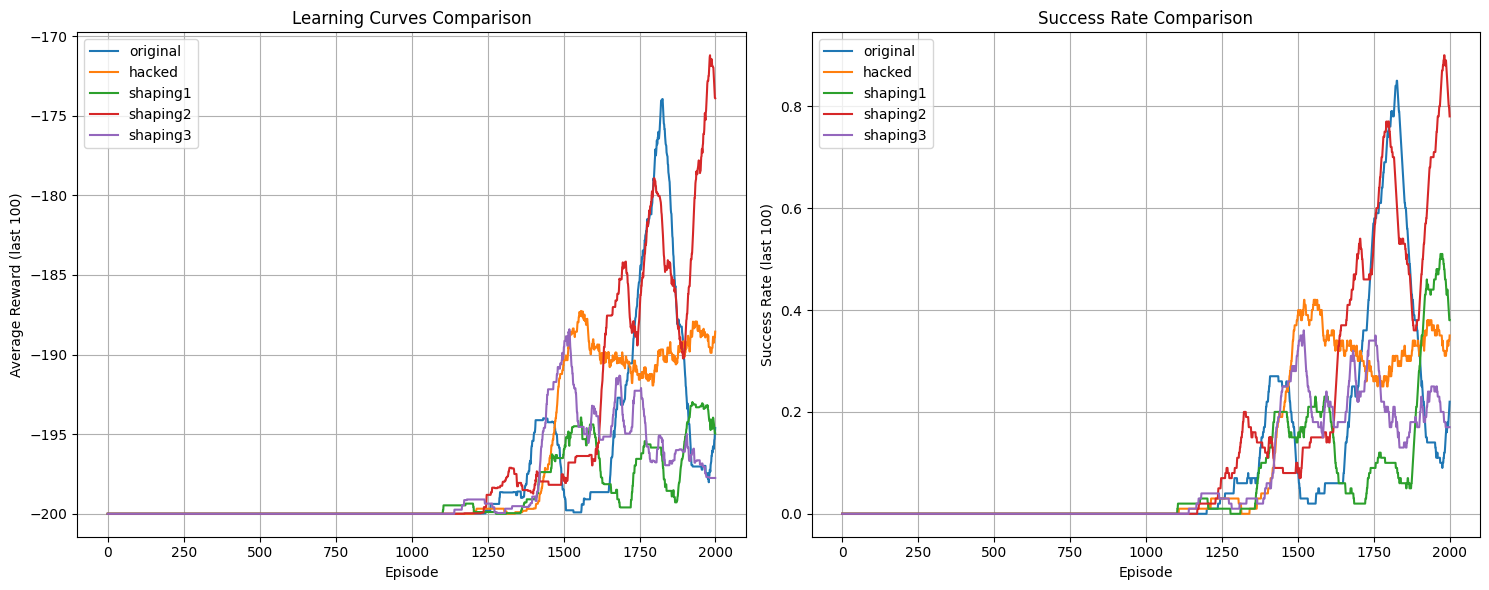

original - Final Success Rate (last 100 episodes): 0.220
hacked - Final Success Rate (last 100 episodes): 0.350
shaping1 - Final Success Rate (last 100 episodes): 0.380
shaping2 - Final Success Rate (last 100 episodes): 0.780
shaping3 - Final Success Rate (last 100 episodes): 0.170


In [72]:
"""
TODO:
Run reward shaping experiments and compare different modes:

1. Define the list of modes:
   ['original', 'hacked', 'shaping1', 'shaping2', 'shaping3']

2. For each mode:
   - Create a new MountainCar-v0 environment.
   - Initialize a ShapedCarAgent with the given mode.
   - Train the agent.
   - Store:
        * Episode rewards (original environment reward)
        * Success flags (0/1)
   - Close the environment.

3. Plot:
   - Smoothed learning curves (moving average of rewards).
   - Smoothed success rates (moving average of success flags).
"""

modes = ['original', 'hacked', 'shaping1', 'shaping2', 'shaping3']
results = {}
for mode in modes:
    print(f"\n--- Training with mode: {mode} ---")
    env = gym.make('MountainCar-v0')
    
    agent = ShapedCarAgent(
        env=env,
        buckets=(20, 20),
        alpha=0.3,
        gamma=0.99,
        episodes=2000,
        mode=mode,
        seed=400
    )
    
    scores, successes = agent.train()
    
    results[mode] = {
        'scores': scores,
        'successes': successes
    }
    
    env.close()

plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
for mode in modes:
    avg_scores = []
    for i in range(len(results[mode]['scores'])):
        start = max(0, i - 99)
        avg_scores.append(np.mean(results[mode]['scores'][start:i+1]))
    plt.plot(avg_scores, label=mode)
plt.xlabel('Episode')
plt.ylabel('Average Reward (last 100)')
plt.title('Learning Curves Comparison')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
for mode in modes:
    success_rate = []
    successes = results[mode]['successes']
    for i in range(len(successes)):
        start = max(0, i - 99)
        success_rate.append(np.mean(successes[start:i+1]))
    plt.plot(success_rate, label=mode)
plt.xlabel('Episode')
plt.ylabel('Success Rate (last 100)')
plt.title('Success Rate Comparison')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

for mode in modes:
    final_success_rate = np.mean(results[mode]['successes'][-100:])
    print(f"{mode} - Final Success Rate (last 100 episodes): {final_success_rate:.3f}")